        # Capstone · The Cooperative's Selling Advisor
        ### From forecasts to decisions: models, uncertainty, and a backtested store-or-sell policy

        | | |
        |---|---|
        | ⏱️ **Time** | about 240 minutes |
        | 📚 **Before you start** | All of Phases 7 and 8 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Run a complete, leak-free **forecasting study** with baselines, statistical/ML models and an honest champion
- Produce **prediction intervals** and **check their calibration** (then fix them)
- Turn forecasts into a **decision policy** and **backtest** it against 'sell now', 'always store' and a perfect-foresight oracle
- Quantify **uncertainty in the conclusion itself** with a bootstrap, and write a board-ready recommendation

> 🌾 **The story so far.** The board has a storage shed and a question every week: **sell the onions now, or store them six weeks for a better price?** Storing costs about 1 % of the value per week (spoilage, space, interest). A forecast is only worth what it does to *decisions*, so that is how we'll judge yours.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## The brief

| | |
|---|---|
| **Series** | weekly **onion** price at the **Harbor** market (`COMMODITY`, `MARKET` below; change them *after* everything is green) |
| **Decision** | at every forecast origin: sell now, or **store for `K = 6` weeks** and sell then, paying `1 %` of value per week (6 % total) |
| **Evaluation protocol** | walk-forward: first window 300 weeks, horizon 8, a new origin every 8 weeks (27 origins) |
| **Deliverables** | (1) leaderboard, (2) calibrated prediction intervals, (3) backtest of decision policies with a confidence interval, (4) a one-page recommendation |

### Rubric (100 points)
| Component | Points |
|---|---|
| Models: ≥ 2 baselines + ≥ 2 learned models, evaluated by walk-forward, leak-free | 20 |
| Champion chosen by the metric that matches the decision horizon | 10 |
| Intervals built from **past errors only**, coverage **checked and calibrated** | 20 |
| Decision backtest: policies implemented correctly, oracle and sell-now benchmarks | 20 |
| Bootstrap confidence interval and an honest statement of significance | 15 |
| Recommendation: concise, quantitative, states limitations and next steps | 15 |

> 🎯 *Optional distinction:* add a third learned model of your choice (SARIMAX, LSTM from Lesson 8.11, Random Forest, a combination) and show whether it changes the decisions.

## Step 1 · Data, protocol and candidate models  *(20 pts)*

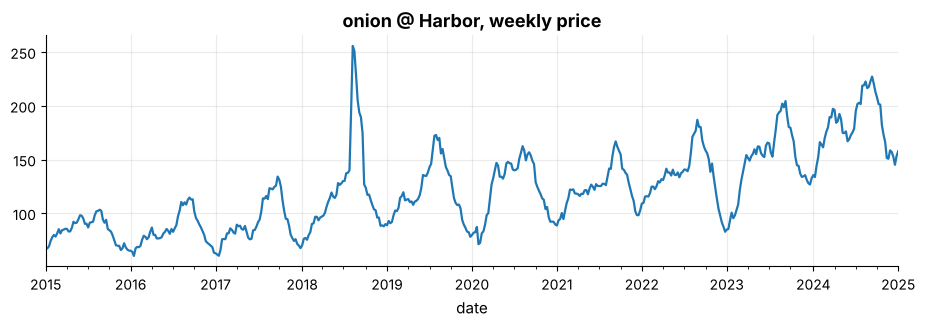

In [2]:
COMMODITY, MARKET = "onion", "Harbor"
K, WEEKLY_COST = 6, 0.01                                  # store for K weeks, losing 1 % of value per week
EVAL = dict(initial=300, horizon=8, step=8)

y = ag.price_series(COMMODITY, MARKET, "W")
rain9 = ag.load_weather().set_index("date")["rainfall_mm"].resample("W").sum().reindex(y.index).rolling(9, min_periods=1).sum()
EXOG = pd.DataFrame({"rain_9w": rain9})
y.plot(figsize=(11, 3), title=f"{COMMODITY} @ {MARKET}, weekly price"); plt.show()

---
### 🧩 Exercise 1: Build the model set  ⭐⭐

Fill the dictionary `candidates` (name → forecaster function `(train, h) -> array`) with **at least four** entries including
`"naive"`, `"seasonal naive"` and two learned models: suggested:
`"Ridge"` = `ag.direct_ml_forecaster(lambda: make_pipeline(StandardScaler(), Ridge(10)), EXOG)` and
`"XGBoost"` = `ag.direct_ml_forecaster(lambda: XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=1), EXOG)`.
Then run walk-forward for all of them with `**EVAL` into `res`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`candidates = {'naive': ag.naive_forecast, 'seasonal naive': ag.seasonal_naive_forecast, ...}`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`res = {name: ag.walk_forward(y, f, **EVAL) for name, f in candidates.items()}`

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Direct ML forecasters rebuild their features from the training slice at each origin, so they cannot leak.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
candidates = {}
res = {}

In [ ]:
try:
    ag.check("at least four models, with both baselines", len(res) >= 4 and {"naive", "seasonal naive"}.issubset(res))
    ag.check("all evaluated on the same 27 origins and 8 horizons", all(r.origin_date.nunique() == 27 and set(r.h) == set(range(1, 9)) for r in res.values()))
    ag.check("at least two non-baseline models", len([k for k in res if k not in ("naive", "seasonal naive")]) >= 2)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## Step 2 · Choose the champion for the *decision* horizon  *(10 pts)*
The shed decision looks **4–8 weeks** ahead, so overall MAE (dominated by easy 1-week forecasts) is the wrong yardstick.
Compute `dec_mae`: for each model, the **average MAE over horizons 4 to 8**, and let `champion` be the best **non-baseline** model.

---
### 🧩 Exercise 2: Decision-horizon scoreboard  ⭐⭐

Build `dec_mae` (a `pd.Series`: model name → mean of the per-horizon MAEs for h = 4…8) and the name `champion`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`r[r.h >= 4].groupby('h').apply(lambda d: ag.mae(d.actual, d.forecast)).mean()` for each model's DataFrame `r`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`dec_mae = pd.Series({name: ... for name, r in res.items()}).sort_values()`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Exclude `'naive'` and `'seasonal naive'` when picking: `champion = dec_mae.drop(['naive', 'seasonal naive']).idxmin()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
dec_mae = None
champion = None

In [ ]:
try:
    ag.check("one score per model", dec_mae is not None and len(dec_mae) == len(res))
    ag.check("champion is a learned (non-baseline) model", champion not in ("naive", "seasonal naive") and champion in res)
    ag.check("champion has the lowest decision-horizon MAE among learned models", champion == dec_mae.drop(["naive", "seasonal naive"]).idxmin())
    ag.check("it clearly beats naive at these horizons (> 30 % lower MAE)", dec_mae[champion] < 0.7 * dec_mae["naive"])
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## Step 3 · Prediction intervals: and a calibration check  *(20 pts)*

A point forecast of "price in 6 weeks = 168" is not a decision aid unless we know *how wrong it may be*. A simple, model-agnostic method: a cousin of **conformal prediction**:

1. For each past forecast, record the **log error** $\log(\text{actual}/\text{forecast})$.
2. At a new origin, take a high quantile of the **past** absolute log errors and set the interval to $\hat y\,e^{\pm q}$.

**Leak rule:** at origin *o* use only errors from origins **before** *o* (with step 8 and horizon ≤ 8, every earlier forecast's outcome is known by *o*).

First, a naive version: quantiles of the *signed* errors of the **same horizon**, nothing else. We'll *measure* whether the "80 % interval" really contains 80 % of outcomes.

In [7]:
def intervals_v1(r, level=0.8, min_origins=5):
    r = r.copy(); r["log_err"] = np.log(r.actual / r.forecast)
    origins = sorted(r.origin_date.unique()); rows = []
    for j, o in enumerate(origins):
        if j < min_origins: continue
        past = r[r.origin_date < o]
        for _, row in r[r.origin_date == o].iterrows():
            pe = past[past.h == row.h].log_err
            lo_q, hi_q = np.quantile(pe, [(1 - level) / 2, 1 - (1 - level) / 2])
            rows.append(dict(origin_date=o, h=row.h, target_date=row.target_date, actual=row.actual, forecast=row.forecast,
                             lo=row.forecast * np.exp(lo_q), hi=row.forecast * np.exp(hi_q)))
    return pd.DataFrame(rows)

iv1 = intervals_v1(res[champion])
cov1 = ((iv1.actual >= iv1.lo) & (iv1.actual <= iv1.hi)).mean()
print(f"Naive 'same-horizon signed quantile' intervals: nominal 80 %, ACTUAL coverage = {cov1:.0%}  ({len(iv1)} forecasts)")

Naive 'same-horizon signed quantile' intervals: nominal 80 %, ACTUAL coverage = 65%  (176 forecasts)


**Under-coverage.** The intervals are too narrow: with only a handful of past errors per horizon the 10th/90th percentiles are *estimated too tightly* (small-sample optimism), and signed errors can offset each other.
Two standard repairs:

1. **Pool neighbouring horizons** (`h-pool … h+pool`) to get more error samples: errors at adjacent horizons are similar in size.
2. Use the **finite-sample conformal quantile**: with $n$ past absolute errors take the $\lceil (n+1)\,\text{level}\rceil/n$ quantile (slightly above the nominal), and a **symmetric** interval $\hat y\,e^{\pm q}$.

---
### 🧩 Exercise 3: Calibrated intervals  ⭐⭐⭐

Implement `pooled_intervals(r, level=0.8, pool=2, min_origins=5)` returning a DataFrame with columns
`origin_date, h, target_date, actual, forecast, lo, hi`, using **only errors from origins before the current one**:
for each forecast row, take `abs_err = |log(actual/forecast)|` of past rows with horizon in `[h-pool, h+pool]`,
let `n = len(abs_err)`, `q = np.quantile(abs_err, min(1, ceil((n+1)*level)/n))`, and set `lo = forecast*exp(-q)`, `hi = forecast*exp(q)`.
Skip the first `min_origins` origins. Apply it to the champion's results → `iv`; store `coverage` (share of actuals inside) and `mean_width_pct` (mean of `(hi-lo)/forecast` × 100).

<details><summary>💡 Hint 1: gentle nudge</summary>

Start from `intervals_v1`; replace the same-horizon signed errors by pooled **absolute** errors: `past[(past.h >= row.h - pool) & (past.h <= row.h + pool)].abs_err`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`q = np.quantile(pe, min(1, np.ceil((n + 1) * level) / n))`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`coverage = ((iv.actual >= iv.lo) & (iv.actual <= iv.hi)).mean()`; `mean_width_pct = ((iv.hi - iv.lo) / iv.forecast).mean() * 100`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def pooled_intervals(r, level=0.8, pool=2, min_origins=5):
    return None

iv = None
coverage = mean_width_pct = None

In [ ]:
try:
    need = {"origin_date", "h", "target_date", "actual", "forecast", "lo", "hi"}
    ag.check("has the required columns", iv is not None and need.issubset(iv.columns))
    ag.check("intervals are valid (lo < forecast < hi)", iv is not None and ((iv.lo < iv.forecast) & (iv.forecast < iv.hi)).all())
    ag.check("coverage is close to the nominal 80 % (0.74 - 0.88)", coverage is not None and 0.74 <= coverage <= 0.88)
    ag.check("it improved on the naive version", coverage is not None and coverage > cov1)
    ag.check("no leakage: the first interval origin is the 6th origin", iv is not None and iv.origin_date.nunique() == 22)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

coverage by horizon: {1: 0.95, 2: 0.82, 3: 0.82, 4: 0.86, 5: 0.73, 6: 0.77, 7: 0.73, 8: 0.77}


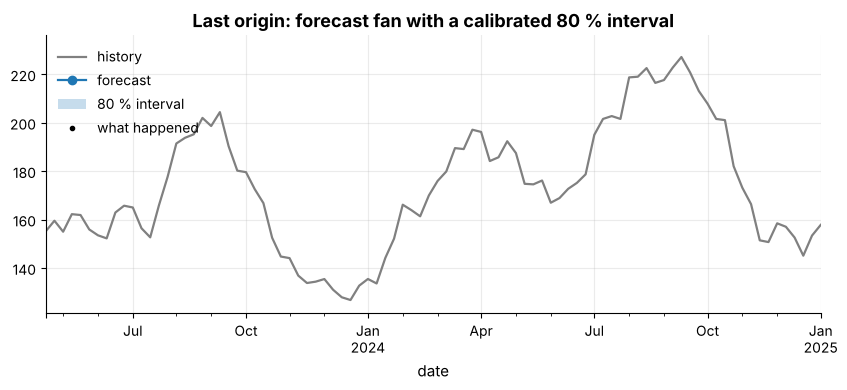

In [10]:
cov_by_h = iv.assign(inside=(iv.actual >= iv.lo) & (iv.actual <= iv.hi)).groupby("h").inside.mean()
print("coverage by horizon:", cov_by_h.round(2).to_dict())
last = iv[iv.origin_date == iv.origin_date.max()]
fig, ax = plt.subplots(figsize=(10, 3.6))
y.iloc[-90:].plot(ax=ax, color="gray", label="history")
ax.plot(last.target_date, last.forecast, "o-", label="forecast"); ax.fill_between(last.target_date, last.lo, last.hi, alpha=.25, label="80 % interval")
ax.plot(last.target_date, last.actual, "k.", label="what happened"); ax.legend(); ax.set_title("Last origin: forecast fan with a calibrated 80 % interval"); plt.show()

## Step 4 · From forecasts to decisions  *(20 pts)*

At each origin the cooperative compares:

- **sell now** → revenue = today's price $y_t$
- **store `K` weeks** → revenue = $y_{t+K}\,(1-\text{WEEKLY\_COST}\times K)$

Five policies:

| Policy | Rule |
|---|---|
| **sell now** | never store |
| **always store** | always store |
| **forecast** | store if *forecast* $\hat y_{t+K}(1-c) > y_t$ |
| **forecast + interval** (cautious) | store only if the **lower bound** $\hat y^{\text{lo}}_{t+K}(1-c) > y_t$: "even in a bad case we win" |
| **oracle** | stores exactly when storing really pays (knows the future; an *upper bound*, unattainable) |

The decision table has one row per origin, using the champion's horizon-`K` forecast and interval:

In [11]:
dec = iv[iv.h == K].copy().reset_index(drop=True)
cost = WEEKLY_COST * K
dec["now"] = y.loc[dec.origin_date].to_numpy()                 # price today, at the forecast origin
dec["store_net"] = dec.actual * (1 - cost)                      # realised revenue if we store
print(len(dec), "decisions | storage cost:", f"{cost:.0%}"); dec[["origin_date", "now", "forecast", "lo", "hi", "actual", "store_net"]].head(4).round(1)

22 decisions | storage cost: 6%


,origin_date,now,forecast,lo,hi,actual,store_net
0,2021-07-04,125.4,162.2,146.3,179.9,141.7,133.2
1,2021-08-29,153.0,141.6,126.0,159.1,141.5,133.0
2,2021-10-24,137.7,98.3,87.9,110.0,101.8,95.7
3,2021-12-19,98.2,104.8,93.9,117.0,115.5,108.5


---
### 🧩 Exercise 4: Implement and compare the policies  ⭐⭐⭐

Using the DataFrame `dec` and `cost`, compute boolean NumPy arrays `store_forecast`, `store_cautious`, `store_oracle`
(rules above; the oracle stores when `store_net > now`) and the **mean revenue** of each policy:
write `mean_revenue(store_flags)` = mean of `np.where(store_flags, dec.store_net, dec.now)` and build `table`: a `pd.DataFrame` with index
`["sell now", "always store", "forecast", "forecast + interval", "oracle"]` and columns `revenue`, `uplift_pct` (vs sell now), `stores_share`.
Finally `captured` = (revenue of forecast policy − sell now) / (oracle − sell now).

<details><summary>💡 Hint 1: gentle nudge</summary>

`store_forecast = (dec.forecast * (1 - cost) > dec.now).to_numpy()`; cautious uses `dec.lo`; oracle uses `dec.store_net > dec.now`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`flags = {'sell now': np.zeros(n, bool), 'always store': np.ones(n, bool), 'forecast': store_forecast, ...}`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`rev = {k: mean_revenue(v) for k, v in flags.items()}`; `uplift_pct = 100 * (rev / rev['sell now'] - 1)`; `stores_share = mean of the flags`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def mean_revenue(store_flags):
    return None

store_forecast = store_cautious = store_oracle = None
table = None
captured = None

In [ ]:
try:
    ag.check("table has the 5 policies", table is not None and list(table.index) == ["sell now", "always store", "forecast", "forecast + interval", "oracle"])
    ag.check("the oracle is the best policy (it knows the future)", table is not None and table.revenue.idxmax() == "oracle")
    ag.check("'always store' loses money after 6 % storage costs", table is not None and table.loc["always store", "uplift_pct"] < 0)
    ag.check("the forecast policy beats 'sell now'", table is not None and table.loc["forecast", "uplift_pct"] > 0)
    ag.check("it captures a meaningful share of the oracle's gain (30 % - 100 %)", captured is not None and 0.3 <= captured <= 1.0)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## Step 5 · Is the gain real? A bootstrap  *(15 pts)*
The uplift is an average over only ~22 decisions. Could luck explain it? **Bootstrap**: resample the *decisions* (with replacement) 2,000 times, recompute the mean advantage of the forecast policy over "sell now" each time,
and read off the 2.5th–97.5th percentiles: a 95 % confidence interval.

---
### 🧩 Exercise 5: Bootstrap confidence interval for the advantage  ⭐⭐

Let `adv` be the per-decision advantage of the forecast policy over selling now:
`adv = np.where(store_forecast, dec.store_net, dec.now) - dec.now`, converted to a **NumPy array** with `.to_numpy()` (so it can be indexed by an integer matrix).
With `rng = np.random.default_rng(0)` draw 2,000 bootstrap resamples of `adv` (same size, with replacement), take the mean of each, and store:
`boot_means` (array of 2,000), `ci_low`, `ci_high` (2.5 and 97.5 percentiles), `point` (the mean of `adv`),
and `significant = ci_low > 0`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`idx = rng.integers(0, len(adv), size=(2000, len(adv)))` creates all resamples at once; `adv[idx].mean(axis=1)` gives the 2,000 means.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`significant = bool(ci_low > 0)`: does the interval exclude zero?

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
rng = np.random.default_rng(0)
adv = None
boot_means = ci_low = ci_high = point = significant = None

In [ ]:
try:
    ag.check("2,000 bootstrap means", boot_means is not None and len(boot_means) == 2000)
    ag.check("the point estimate lies inside its own confidence interval", ci_low is not None and ci_low < point < ci_high)
    ag.check("significant is a bool consistent with the interval", significant == bool(ci_low > 0))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

How to read the result: if the interval excludes 0, the evidence that the forecast policy beats selling now is reasonably strong *given 22 decisions*; if it includes 0, the honest statement is
**"promising but not proven: keep collecting data."** Either way, the *width* tells the board how uncertain the benefit is. (Note the bootstrap treats decisions as independent; neighbouring origins share seasonality and shocks, so real uncertainty is somewhat larger.)

## Step 6 · The recommendation  *(15 pts)*
Write **at most ten sentences** for the board in the string `recommendation`. Include: the champion model and its decision-horizon error versus naive; the interval coverage you *measured*;
the policy results (uplift, share of oracle gain); the bootstrap verdict; **one** limitation; **one** next step.

---
### 🧩 Exercise 6: Board recommendation  ⭐⭐

Write the final recommendation in `recommendation`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Lead with the decision: *should the cooperative adopt the forecast-driven storage rule?*

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Quote: `dec_mae[champion]` vs `dec_mae['naive']`; `coverage`; `table.loc['forecast','uplift_pct']`; `captured`; the bootstrap interval.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Limitations: synthetic data, 22 decisions, storage costs assumed, shocks unpredictable. Next step: pilot on a small share of stock; monitor interval coverage.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
recommendation = """
Decision: ...
Evidence: ...
Uncertainty: ...
Limitation: ...
Next step: ...
"""

In [ ]:
try:
    r_ = recommendation.lower()
    ag.check("a substantial but concise text (400-3000 characters)", isinstance(recommendation, str) and 400 < len(recommendation) < 3000)
    ag.check("mentions the champion model by name", champion.lower() in r_)
    ag.check("quotes numbers (at least 10 digits)", sum(c.isdigit() for c in recommendation) >= 10)
    ag.check("covers uncertainty and limitations", "uncertain" in r_ and "limitation" in r_)
    ag.check("proposes a next step", "next step" in r_)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 🏆 Distinction challenges
1. **Sensitivity.** Re-run Step 4 for `WEEKLY_COST` in {0.5 %, 1 %, 1.5 %, 2 %} and `K` in {4, 6, 8}. Plot uplift vs cost: at what storage cost does the forecast stop paying?
2. **A third model.** Add the LSTM from Lesson 8.11 or a SARIMAX with Fourier terms; does the champion or the policy result change?
3. **Asymmetric intervals.** Use separate quantiles for over- and under-forecasts; check coverage of each tail.
4. **Other crops/markets.** Loop the whole pipeline over all 12 series; tabulate uplift and calibration. Which crop benefits most from storage?
5. **Policy tuning.** Add a *margin* (store only if forecast gain exceeds `m %`) and choose `m` on the first 11 decisions, test on the rest, without peeking.
6. **Reality check.** What would change if prices at the time of sale also depended on *your* volume (market impact)?

## 📝 Submission checklist
- [ ] Restart & Run All completes · [ ] every check green · [ ] figures titled and labelled
- [ ] `recommendation` ≤ 10 sentences with numbers · [ ] you can explain, without notes: *why* the intervals first under-covered, and why "always store" lost money

## 🎓 Final reflection (answer in your own notes)
1. Which single decision in this project most protected you from fooling yourself?
2. Where would the system break first in production?
3. What would you monitor weekly after launch?

        ---
        ## 🧾 Recap
        - A forecast's value is measured **in decisions**: choose models by the horizon the decision needs.
- Intervals must be built from **past errors only** and **checked for calibration**: the first attempt under-covered.
- Backtest policies against **sell-now, always-store and an oracle**; the oracle shows the ceiling.
- Quantify the uncertainty of the *conclusion* itself (bootstrap), and state limitations plainly.
- You have now carried a project from raw prices to a board-ready recommendation: **that is data science.**

**Next up:** Congratulations, Professor-in-training. Take the techniques to real data, and keep checking your own work.